In [2]:
import pandas as pd
import numpy as np
from scipy import stats

path = r'C:\Users\13676\Desktop\senna_cohort.csv'
df = pd.read_csv(path, encoding='gb18030',
                 encoding_errors='replace', low_memory=False)

time_cols = ['index_time', 'baseline_k_charttime', 'hypokalemia_time',
             'window_event_time', 'admittime', 'dischtime', 'deathtime',
             'baseline_egfr_charttime']
for c in time_cols:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], dayfirst=True, errors='coerce')

df_main = df.dropna(subset=['senna_exposed', 'hypokalemia_event',
                             'baseline_k', 'age']).copy()
df_main['y'] = df_main['hypokalemia_event'].astype(int)
df_main['senna_exposed'] = df_main['senna_exposed'].astype(int)
df_main['gender_male'] = (df_main['gender'].str.upper().str[0] == 'M').astype(int)

print('df_main 行数:', len(df_main))
print('暴露组:', (df_main['senna_exposed']==1).sum())
print('低钾事件:', df_main['y'].sum())

df_main 行数: 41529
暴露组: 24226
低钾事件: 8752


In [3]:
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

ml_features = [
    'senna_exposed', 'gender_male',
    'age_75_84', 'age_85plus',
    'baseline_k', 'baseline_creatinine', 'baseline_egfr',
    'drug_count_no_laxatives',
    'chf', 'ckd', 'dm',
    'diuretic', 'acei_arb', 'digoxin', 'insulin', 'statin', 'anticoagulant',
    'lactulose', 'peg', 'bisacodyl',
    'ppi', 'beta2_agonist', 'corticosteroid',
]

df_ml = df_main.copy()
df_ml['age_75_84']  = (df_ml['age_group'] == '75-84').astype(int)
df_ml['age_85plus'] = (df_ml['age_group'] == '85+').astype(int)
df_ml = df_ml[ml_features + ['y']].copy()
for c in ml_features:
    df_ml[c] = pd.to_numeric(df_ml[c], errors='coerce')

X = df_ml[ml_features]
y = df_ml['y']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)
train_median = X_train.median()
X_train = X_train.fillna(train_median)
X_test  = X_test.fillna(train_median)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# XGBoost
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()
xgb_model = xgb.XGBClassifier(
    max_depth=5, learning_rate=0.05, n_estimators=300,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=scale_pos,
    random_state=42, eval_metric='logloss')
xgb_model.fit(X_train, y_train)

# LASSO
lasso_base = LogisticRegression(
    penalty='l1', solver='saga', class_weight='balanced',
    max_iter=5000, random_state=42)
grid = GridSearchCV(lasso_base,
                    param_grid={'C': [0.01, 0.05, 0.1, 0.5, 1, 5, 10, 50, 100]},
                    scoring='roc_auc',
                    cv=StratifiedKFold(5, shuffle=True, random_state=42),
                    n_jobs=-1)
grid.fit(X_train_scaled, y_train)
lasso_model = grid.best_estimator_

print('模型重建完成')
print('XGBoost AUC:', round(__import__('sklearn.metrics').metrics.roc_auc_score(
    y_test, xgb_model.predict_proba(X_test)[:,1]), 4))
print('LASSO C =', grid.best_params_['C'])

模型重建完成
XGBoost AUC: 0.7439
LASSO C = 0.05


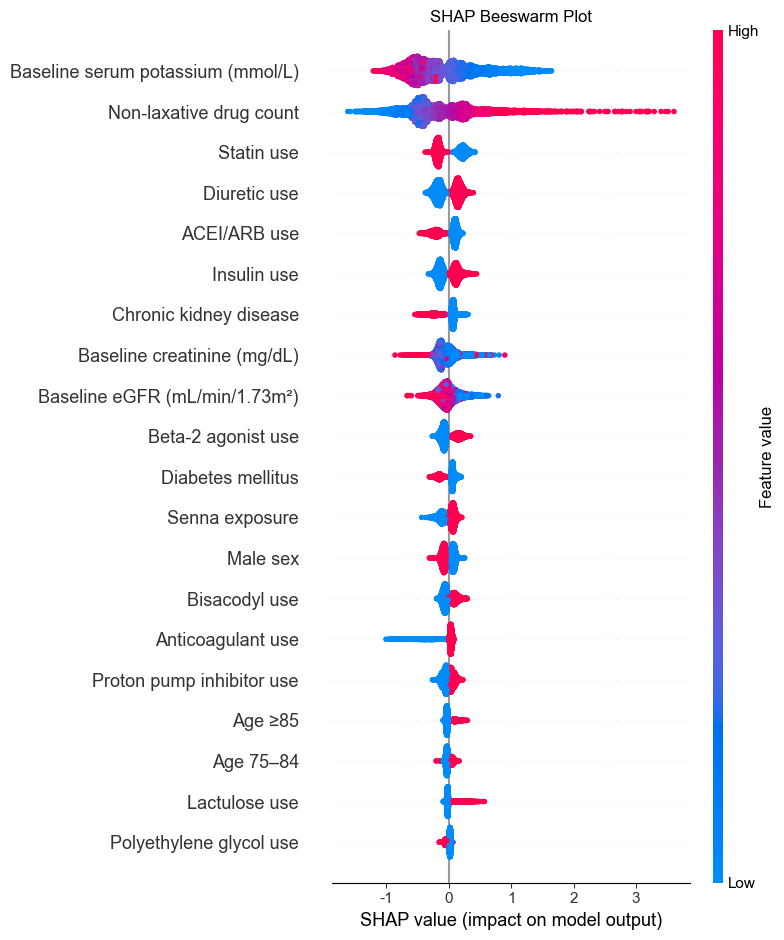

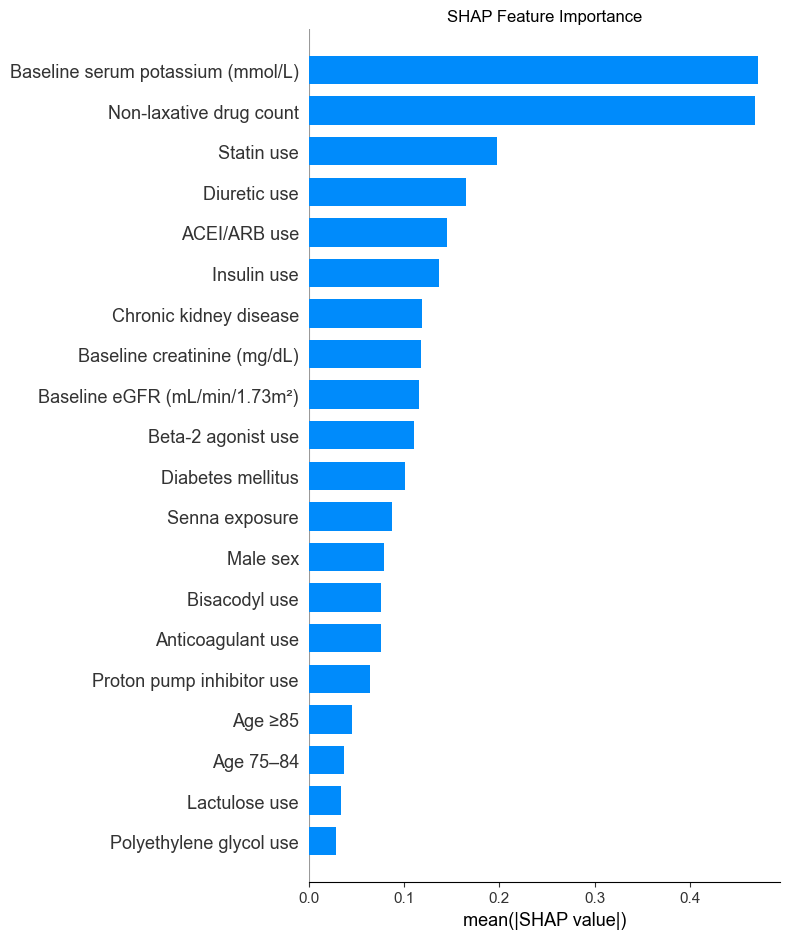

In [4]:
import shap
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['font.sans-serif'] = ['Arial']
mpl.rcParams['axes.unicode_minus'] = False
mpl.rcParams['savefig.dpi'] = 300

feature_name_map = {
    'senna_exposed': 'Senna exposure',
    'gender_male': 'Male sex',
    'age_75_84': 'Age 75–84',
    'age_85plus': 'Age ≥85',
    'baseline_k': 'Baseline serum potassium (mmol/L)',
    'baseline_creatinine': 'Baseline creatinine (mg/dL)',
    'baseline_egfr': 'Baseline eGFR (mL/min/1.73m²)',
    'drug_count_no_laxatives': 'Non-laxative drug count',
    'chf': 'Congestive heart failure',
    'ckd': 'Chronic kidney disease',
    'dm': 'Diabetes mellitus',
    'diuretic': 'Diuretic use',
    'acei_arb': 'ACEI/ARB use',
    'digoxin': 'Digoxin use',
    'insulin': 'Insulin use',
    'statin': 'Statin use',
    'anticoagulant': 'Anticoagulant use',
    'lactulose': 'Lactulose use',
    'peg': 'Polyethylene glycol use',
    'bisacodyl': 'Bisacodyl use',
    'ppi': 'Proton pump inhibitor use',
    'beta2_agonist': 'Beta-2 agonist use',
    'corticosteroid': 'Corticosteroid use',
}

X_test_renamed = X_test.rename(columns=feature_name_map)
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_renamed)

with mpl.rc_context({'font.family': 'Arial'}):
    plt.figure(figsize=(9, 8))
    shap.summary_plot(shap_values, X_test_renamed, show=False)
    plt.xlabel('SHAP value (impact on model output)', family='Arial')
    plt.title('SHAP Beeswarm Plot', family='Arial')
    plt.tight_layout()
    plt.savefig('Figure_SHAP_beeswarm.png', dpi=300, bbox_inches='tight')
    plt.show()

with mpl.rc_context({'font.family': 'Arial'}):
    plt.figure(figsize=(8, 7))
    shap.summary_plot(shap_values, X_test_renamed,
                      plot_type='bar', show=False)
    plt.xlabel('mean(|SHAP value|)', family='Arial')
    plt.title('SHAP Feature Importance', family='Arial')
    plt.tight_layout()
    plt.savefig('Figure_SHAP_bar.png', dpi=300, bbox_inches='tight')
    plt.show()

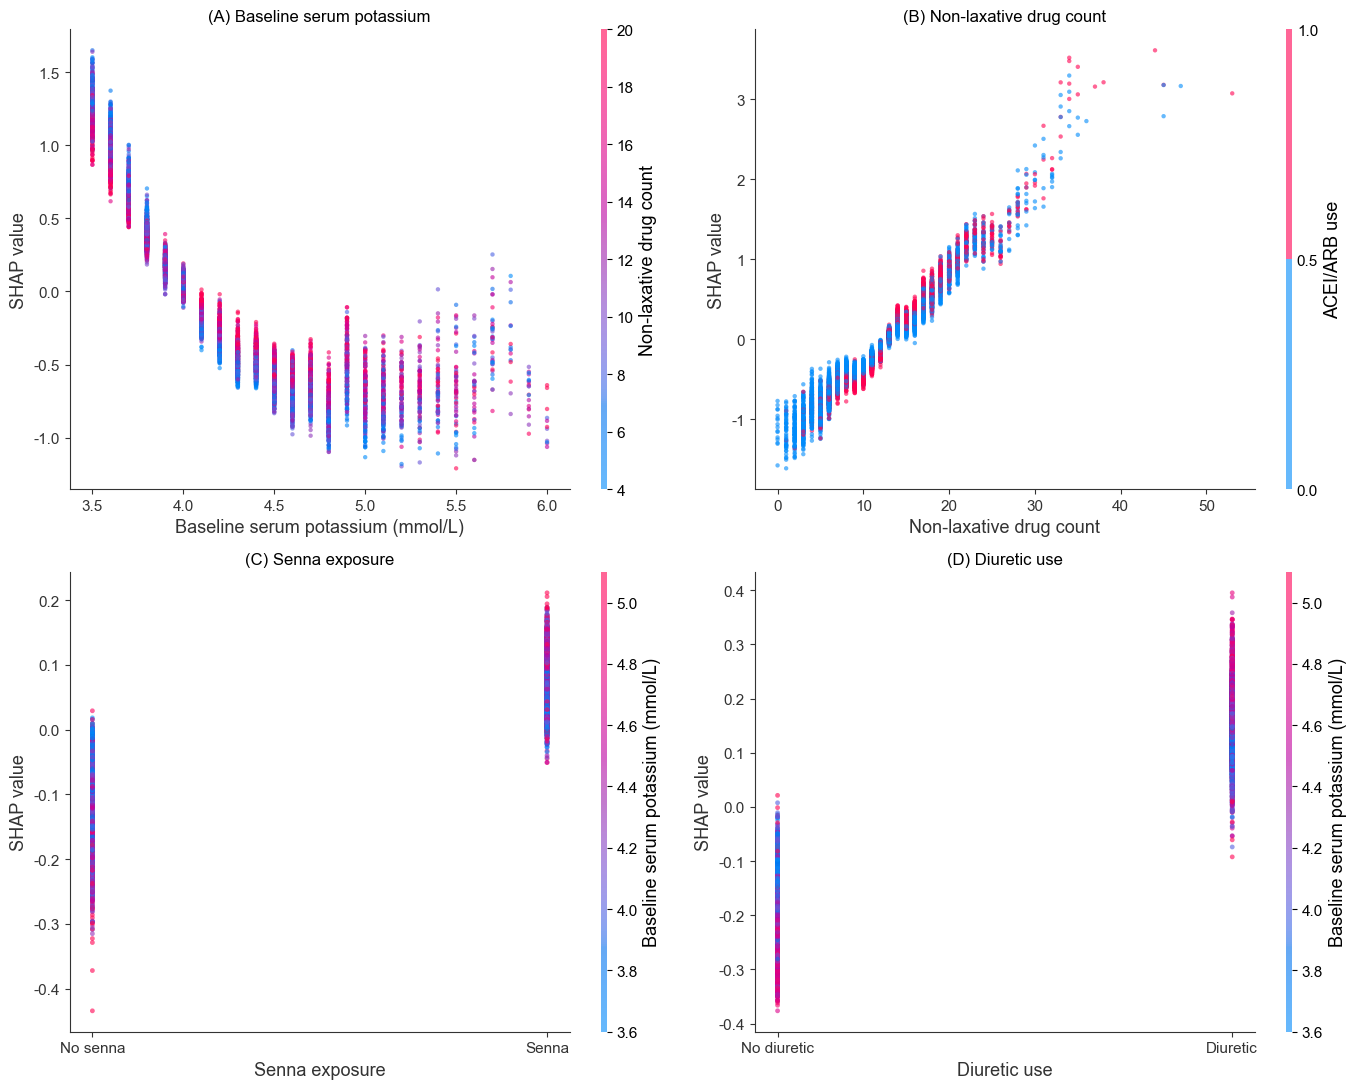

In [5]:
import shap
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['font.sans-serif'] = ['Arial']
mpl.rcParams['axes.unicode_minus'] = False

k_name     = 'Baseline serum potassium (mmol/L)'
drug_name  = 'Non-laxative drug count'
senna_name = 'Senna exposure'
diur_name  = 'Diuretic use'

with mpl.rc_context({'font.family': 'Arial'}):
    fig, axes = plt.subplots(2, 2, figsize=(14, 11))

    shap.dependence_plot(k_name, shap_values, X_test_renamed,
                         interaction_index='auto',
                         show=False, ax=axes[0,0], dot_size=10, alpha=0.6)
    axes[0,0].set_title('(A) Baseline serum potassium', family='Arial')
    axes[0,0].set_xlabel('Baseline serum potassium (mmol/L)', family='Arial')
    axes[0,0].set_ylabel('SHAP value', family='Arial')

    shap.dependence_plot(drug_name, shap_values, X_test_renamed,
                         interaction_index='auto',
                         show=False, ax=axes[0,1], dot_size=10, alpha=0.6)
    axes[0,1].set_title('(B) Non-laxative drug count', family='Arial')
    axes[0,1].set_xlabel('Non-laxative drug count', family='Arial')
    axes[0,1].set_ylabel('SHAP value', family='Arial')

    shap.dependence_plot(senna_name, shap_values, X_test_renamed,
                         interaction_index=k_name,
                         show=False, ax=axes[1,0], dot_size=12, alpha=0.6)
    axes[1,0].set_title('(C) Senna exposure', family='Arial')
    axes[1,0].set_xlabel('Senna exposure', family='Arial')
    axes[1,0].set_ylabel('SHAP value', family='Arial')
    axes[1,0].set_xticks([0,1])
    axes[1,0].set_xticklabels(['No senna','Senna'], family='Arial')

    shap.dependence_plot(diur_name, shap_values, X_test_renamed,
                         interaction_index=k_name,
                         show=False, ax=axes[1,1], dot_size=12, alpha=0.6)
    axes[1,1].set_title('(D) Diuretic use', family='Arial')
    axes[1,1].set_xlabel('Diuretic use', family='Arial')
    axes[1,1].set_ylabel('SHAP value', family='Arial')
    axes[1,1].set_xticks([0,1])
    axes[1,1].set_xticklabels(['No diuretic','Diuretic'], family='Arial')

    plt.tight_layout()
    plt.savefig('Figure_SHAP_dependence_panel.png', dpi=300, bbox_inches='tight')
    plt.show()

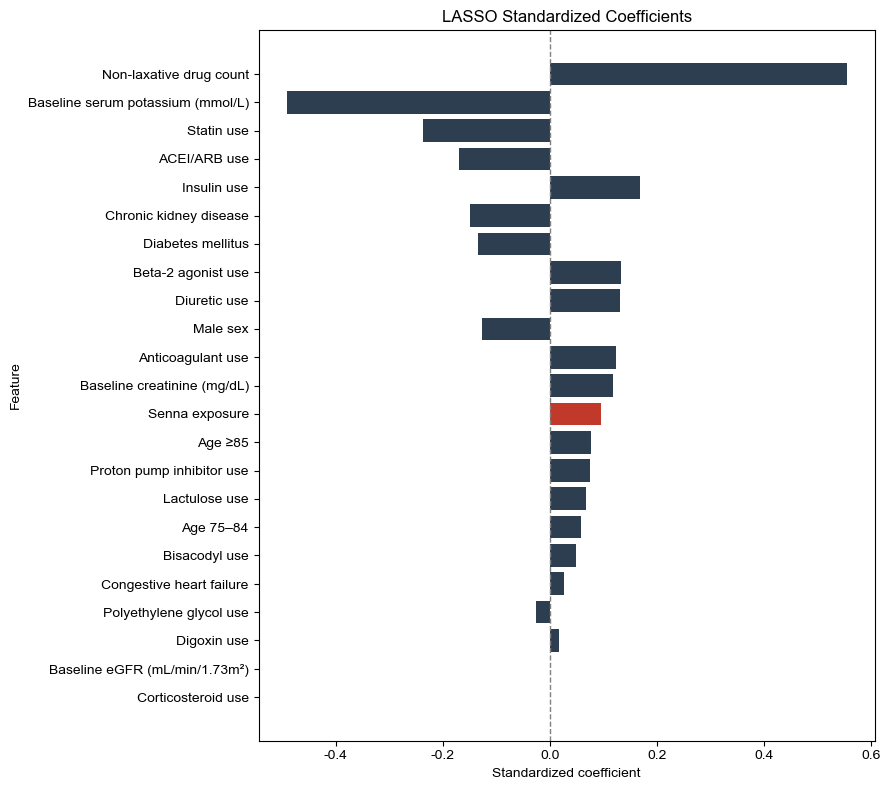

In [6]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['font.sans-serif'] = ['Arial']
mpl.rcParams['axes.unicode_minus'] = False

coef_df = pd.DataFrame({
    'Feature': ml_features,
    'Coefficient': lasso_model.coef_[0]
})
coef_df['Feature'] = coef_df['Feature'].map(feature_name_map)
coef_df = coef_df.sort_values('Coefficient', key=abs,
                              ascending=False).reset_index(drop=True)

with mpl.rc_context({'font.family': 'Arial'}):
    fig, ax = plt.subplots(figsize=(9, 8))
    colors = ['#C0392B' if f == 'Senna exposure' else '#2C3E50'
              for f in coef_df['Feature']]
    ax.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors)
    ax.axvline(0, color='gray', linestyle='--', linewidth=1)
    ax.set_xlabel('Standardized coefficient', family='Arial')
    ax.set_ylabel('Feature', family='Arial')
    ax.set_title('LASSO Standardized Coefficients', family='Arial')
    ax.invert_yaxis()
    ax.tick_params(axis='y', labelsize=10)
    for tick in ax.get_yticklabels():
        tick.set_fontfamily('Arial')
    plt.tight_layout()
    plt.savefig('Figure_LASSO_coefficients.png', dpi=300, bbox_inches='tight')
    plt.show()

In [7]:
import pickle
with open('ml_results.pkl', 'wb') as f:
    pickle.dump({
        'ml_features': ml_features,
        'feature_name_map': feature_name_map,
        'X_test': X_test, 'y_test': y_test,
        'X_test_renamed': X_test_renamed,
        'xgb_model': xgb_model, 'lasso_model': lasso_model,
        'shap_values': shap_values,
    }, f)
print('已保存 ml_results.pkl')

已保存 ml_results.pkl
